# SG-SC v2: Similarity-Gated, Error-Weighted SLERP Composition — Assignment 2

This notebook implements and evaluates Similarity-Gated, Error-Weighted
SLERP Composition (SG-SC) for affine merging of adjacent GPT-2 layers.

The method uses three stages:

1. **Stage 1 — Compatibility Gate:** A representation-compatibility score
   determines whether a pair is considered safe to merge. Pairs below the
   threshold fall back to Remove.

2. **Stage 2 — Calibration-Based Weighting:** For pairs that pass the gate,
   Average and Multiply candidates are evaluated using hidden-state
   reconstruction error on a held-out calibration split. This calibration
   error determines the weighting between the two candidates.

3. **Stage 3 — SLERP Composition:** The Average and Multiply candidates are
   combined using spherical linear interpolation (SLERP).

The notebook also evaluates SG-SC ablations, including NoGate, FixedWeight,
Linear, and CompatWeight, and compares the methods across all 11 adjacent
GPT-2 layer pairs.

The final experiment uses `MODE = "full"` and evaluates the selected
configuration on the held-out test set only after validation-based selection.

In [ ]:
!pip install -q transformers==5.16.1 datasets accelerate pandas psutil

In [ ]:
import gc
import math
import random
import time
import copy
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import matplotlib.pyplot as plt

from datasets import load_dataset
from transformers import AutoTokenizer, AutoModelForCausalLM

# ============================================================
# 0. CONFIGURATION  (same as Assignment 1)
# ============================================================

MODEL_ID = "openai-community/gpt2"
SEED = 42
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
DTYPE = torch.float32  # model and all fitted affine maps stay in fp32 throughout

# "quick" = development/debugging only. Switch to "full" for real numbers.
import os
MODE = os.environ.get("SGSC_MODE", "full")
OUTPUT_DIR = os.environ.get("SGSC_OUTPUT_DIR", "/content" if os.path.isdir("/content") else "./sgsc_outputs")
os.makedirs(OUTPUT_DIR, exist_ok=True)

TOKENIZER_NAME = MODEL_ID  # GPT-2's own BPE tokenizer, no custom vocab
SEQ_LEN_FOR_LATENCY = 256   # fixed sequence length used by every latency measurement

if MODE == "quick":
    FIT_TOKENS = 4096
    CALIB_TOKENS = 4096
    EVAL_TOKENS = 10000
    RANDOM_RUNS = 3
    LATENCY_REPEATS = 10
else:
    FIT_TOKENS = 20000
    CALIB_TOKENS = 20000
    EVAL_TOKENS = 50000
    RANDOM_RUNS = 5
    LATENCY_REPEATS = 30

if MODE == "quick":
    print("WARNING: MODE='quick' -- these are development numbers, not report numbers.")

EVAL_BLOCK_SIZE = 512
STATE_CHUNK_SIZE = 256
RIDGE = 1e-4

PAIR_STARTS = list(range(11))

# ---- Reproducibility block: everything a report/reader needs to reproduce
# this run without reading the rest of the notebook. ----
import transformers, datasets as datasets_pkg
print("===== REPRODUCIBILITY INFO =====")
import sys, platform
print("python        :", sys.version.split()[0], "|", platform.platform())
print("torch         :", torch.__version__)
print("transformers  :", transformers.__version__)
print("datasets      :", datasets_pkg.__version__)
print("numpy         :", np.__version__)
print("pandas        :", pd.__version__)
print("model_id      :", MODEL_ID)
print("tokenizer     :", TOKENIZER_NAME)
print("device        :", DEVICE, "|", torch.cuda.get_device_name(0) if torch.cuda.is_available() else f"CPU ({platform.processor() or platform.machine()}, torch threads={torch.get_num_threads()})")
print("output_dir    :", OUTPUT_DIR)
print("dtype         :", DTYPE)
print("seed          :", SEED)
print("mode          :", MODE)
print("fit_tokens    :", FIT_TOKENS, "| calib_tokens:", CALIB_TOKENS, "| eval_tokens:", EVAL_TOKENS)
print("eval_block_size:", EVAL_BLOCK_SIZE, "| latency_seq_len:", SEQ_LEN_FOR_LATENCY, "| latency_repeats:", LATENCY_REPEATS)
print("ridge lambda  :", RIDGE)
print("random_runs (Random-Weight Average):", RANDOM_RUNS)
print("pairs         :", [(L, L + 1) for L in PAIR_STARTS])
print("=================================")
print()
print("NOTE: torch.manual_seed makes weight-shuffling and Python/numpy RNG")
print("reproducible; it does NOT guarantee bit-identical PPL across GPUs or")
print("cuDNN versions, since some cuDNN kernels are nondeterministic by")
print("default. If exact repeatability across machines matters, also set")
print("torch.use_deterministic_algorithms(True) -- left off by default here")
print("because it can silently error on ops without a deterministic kernel.")


def set_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

set_seed()

===== REPRODUCIBILITY INFO =====
python        : 3.13.15 | Linux-6.6.122+-x86_64-with-glibc2.39
torch         : 2.11.0+cu128
transformers  : 5.16.1
datasets      : 4.8.5
numpy         : 2.1.3
pandas        : 2.2.3
model_id      : openai-community/gpt2
tokenizer     : openai-community/gpt2
device        : cuda | Tesla T4
output_dir    : /content
dtype         : torch.float32
seed          : 42
mode          : full
fit_tokens    : 20000 | calib_tokens: 20000 | eval_tokens: 50000
eval_block_size: 512 | latency_seq_len: 256 | latency_repeats: 30
ridge lambda  : 0.0001
random_runs (Random-Weight Average): 5
pairs         : [(0, 1), (1, 2), (2, 3), (3, 4), (4, 5), (5, 6), (6, 7), (7, 8), (8, 9), (9, 10), (10, 11)]

NOTE: torch.manual_seed makes weight-shuffling and Python/numpy RNG
reproducible; it does NOT guarantee bit-identical PPL across GPUs or
cuDNN versions, since some cuDNN kernels are nondeterministic by
default. If exact repeatability across machines matters, also set
torch.use_det

In [ ]:
import os

print("MODE =", MODE)
print("OUTPUT_DIR =", OUTPUT_DIR)

print("\n===== FILES IN OUTPUT DIRECTORY =====")
for f in sorted(os.listdir(OUTPUT_DIR)):
    print(f)

MODE = full
OUTPUT_DIR = /content

===== FILES IN OUTPUT DIRECTORY =====
.config
sample_data


In [ ]:
# ============================================================
# 1. DATASET: WIKITEXT-2  (same as Assignment 1, plus a calibration split)
#
# Fit split:         first FIT_TOKENS of train_text.
# Calibration split:  from the SECOND HALF of train_text, so it does not
#                      overlap the text used to fit A1,b1,A2,b2. This is an
#                      approximate (character-offset, not token-exact) split
#                      -- good enough for a course project, and it is what
#                      Stage 2's E_avg/E_mul comparison is computed on, kept
#                      separate from validation so validation is used only
#                      for pair/hyperparameter selection (see Section 11).
# ============================================================

dataset = load_dataset("Salesforce/wikitext", "wikitext-2-raw-v1")

def join_nonempty(split):
    return "\n\n".join(x for x in split["text"] if x is not None and x.strip())

train_text = join_nonempty(dataset["train"])
validation_text = join_nonempty(dataset["validation"])
test_text = join_nonempty(dataset["test"])

calib_text = train_text[len(train_text) // 2:]

print(dataset)
print("train_text chars:", len(train_text), "| calib_text chars:", len(calib_text))

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

wikitext-2-raw-v1/test-00000-of-00001.pa(…): reconstructing file:   0%|          |  0.00B /  733kB            

wikitext-2-raw-v1/test-00000-of-00001.pa(…): downloading bytes:           |  0.00B            

wikitext-2-raw-v1/train-00000-of-00001.p(…): reconstructing file:   0%|          |  0.00B / 6.36MB            

wikitext-2-raw-v1/train-00000-of-00001.p(…): downloading bytes:           |  0.00B            

...

wikitext-2-raw-v1/validation-00000-of-00(…): downloading bytes:           |  0.00B            

Generating test split:   0%|          | 0/4358 [00:00<?, ? examples/s]

Generating train split:   0%|          | 0/36718 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/3760 [00:00<?, ? examples/s]

DatasetDict({
    test: Dataset({
        features: ['text'],
        num_rows: 4358
    })
    train: Dataset({
        features: ['text'],
        num_rows: 36718
    })
    validation: Dataset({
        features: ['text'],
        num_rows: 3760
    })
})
train_text chars: 10940522 | calib_text chars: 5470261


In [ ]:
# ============================================================
# 2. GPT-2  (same as Assignment 1)
# ============================================================

tokenizer = AutoTokenizer.from_pretrained(MODEL_ID)
tokenizer.model_max_length = int(1e12)

def load_fresh_model():
    model = AutoModelForCausalLM.from_pretrained(MODEL_ID)
    model.config.use_cache = False
    model.eval()
    return model

original_model = load_fresh_model().to(DEVICE)

print("Number of Transformer blocks:", len(original_model.transformer.h))
print("Hidden size:", original_model.config.n_embd)

config.json:   0%|          | 0.00/665 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/26.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/1.04M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  548MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/124 [00:00<?, ?B/s]

Number of Transformer blocks: 12
Hidden size: 768


In [ ]:
# ============================================================
# 3. METRICS  (same as Assignment 1, except measure_latency now reports
#    mean AND std across repeats, timed per-call rather than as one block)
# ============================================================

@torch.no_grad()
def calculate_ppl(model, text, block_size=EVAL_BLOCK_SIZE, max_tokens=EVAL_TOKENS):
    model.eval()
    ids = tokenizer(text, return_tensors="pt", add_special_tokens=False)["input_ids"][0]
    if max_tokens is not None:
        ids = ids[:max_tokens]
    n_blocks = len(ids) // block_size
    if n_blocks == 0:
        raise ValueError("Not enough tokens for one evaluation block.")
    total_nll, total_pred_tokens = 0.0, 0
    for i in range(n_blocks):
        x = ids[i * block_size:(i + 1) * block_size].unsqueeze(0).to(DEVICE)
        outputs = model(input_ids=x, labels=x, use_cache=False)
        count = x.numel() - 1
        total_nll += outputs.loss.item() * count
        total_pred_tokens += count
    return math.exp(total_nll / total_pred_tokens)


def parameter_count(model):
    return sum(p.numel() for p in model.parameters())


@torch.no_grad()
def measure_latency(model, text, seq_len=SEQ_LEN_FOR_LATENCY, repeats=LATENCY_REPEATS):
    """Returns (mean_ms, std_ms), timed per-call so std is meaningful."""
    model.eval()
    ids = tokenizer(text, return_tensors="pt", add_special_tokens=False)["input_ids"][:, :seq_len].to(DEVICE)
    for _ in range(5):
        _ = model(ids, use_cache=False)
    if torch.cuda.is_available():
        torch.cuda.synchronize()

    times_ms = []
    for _ in range(repeats):
        if torch.cuda.is_available():
            torch.cuda.synchronize()
        start = time.perf_counter()
        _ = model(ids, use_cache=False)
        if torch.cuda.is_available():
            torch.cuda.synchronize()
        times_ms.append((time.perf_counter() - start) * 1000.0)

    times_ms = np.array(times_ms)
    return float(times_ms.mean()), float(times_ms.std())


def free_model(model):
    del model
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()


baseline_ppl = calculate_ppl(original_model, validation_text)
baseline_params = parameter_count(original_model)
baseline_latency_mean, baseline_latency_std = measure_latency(original_model, validation_text)

print("\n===== ORIGINAL GPT-2 =====")
print("Validation PPL   :", baseline_ppl)
print("Parameters       :", f"{baseline_params:,}")
print(f"Latency (ms)     : {baseline_latency_mean:.3f} +/- {baseline_latency_std:.3f}")

[transformers] `loss_type=None` was set in the config but it is unrecognized. Using the default loss: `ForCausalLMLoss`.



===== ORIGINAL GPT-2 =====
Validation PPL   : 32.904633508501966
Parameters       : 124,439,808
Latency (ms)     : 22.725 +/- 5.068


In [ ]:
# ============================================================
# 4. COLLECT HIDDEN STATES FOR A PAIR  (same as Assignment 1)
#
# X  = input to block L
# Y1 = output of block L
# Y2 = output of block L+1
# ============================================================

def _as_tensor(output):
    if isinstance(output, (tuple, list)):
        return output[0]
    return output


@torch.no_grad()
def collect_pair_states(model, text, L, total_tokens=FIT_TOKENS, chunk_size=STATE_CHUNK_SIZE):
    ids = tokenizer(text, return_tensors="pt", add_special_tokens=False)["input_ids"][0]
    ids = ids[:total_tokens]

    X_list, Y1_list, Y2_list = [], [], []
    d = model.config.n_embd

    def pre_hook_L(module, inputs):
        h = inputs[0].detach()
        X_list.append(h.reshape(-1, d).cpu().float())

    def post_hook_L(module, inputs, output):
        h = _as_tensor(output).detach()
        Y1_list.append(h.reshape(-1, d).cpu().float())

    def post_hook_L1(module, inputs, output):
        h = _as_tensor(output).detach()
        Y2_list.append(h.reshape(-1, d).cpu().float())

    handles = [
        model.transformer.h[L].register_forward_pre_hook(pre_hook_L),
        model.transformer.h[L].register_forward_hook(post_hook_L),
        model.transformer.h[L + 1].register_forward_hook(post_hook_L1),
    ]
    try:
        for start in range(0, len(ids), chunk_size):
            x = ids[start:start + chunk_size]
            if x.numel() < 2:
                continue
            _ = model(x.unsqueeze(0).to(DEVICE), use_cache=False)
    finally:
        for h in handles:
            h.remove()

    return (torch.cat(X_list, dim=0), torch.cat(Y1_list, dim=0), torch.cat(Y2_list, dim=0))

In [ ]:
# ============================================================
# 5. FIT EFFECTIVE AFFINE MAPS  (same as Assignment 1)
#
# Row-vector convention: Y ~= X @ A + b
# ============================================================

def fit_affine(X, Y, ridge=RIDGE):
    X = X.double()
    Y = Y.double()
    x_mean = X.mean(dim=0, keepdim=True)
    y_mean = Y.mean(dim=0, keepdim=True)
    Xc = X - x_mean
    Yc = Y - y_mean
    gram = Xc.T @ Xc
    diag_scale = gram.diag().mean().clamp_min(1e-12)
    reg = ridge * diag_scale * torch.eye(gram.shape[0], dtype=gram.dtype)
    A = torch.linalg.solve(gram + reg, Xc.T @ Yc)
    b = (y_mean - x_mean @ A).squeeze(0)
    return A.float(), b.float()


def hidden_mse(X, Y_true, A, b):
    with torch.no_grad():
        Y_hat = X @ A + b
        return torch.mean((Y_hat - Y_true) ** 2).item()

In [ ]:
# ============================================================
# 6. THE FOUR ORIGINAL CONDITIONS + MODEL BUILDER  (same as Assignment 1)
#
# Terminology note: "Remove" here means (A2, b2) -- the fitted affine
# approximation of block L+1 alone -- NOT the literal untouched
# Transformer block, exactly as in Assignment 1's own affine-comparison
# table. All four conditions replace the pair with a single nn.Linear
# affine surrogate; none of them keep a real nonlinear Transformer block.
# The project's claim is about the affine-approximation framework
# Assignment 1 established, not about merging real blocks directly.
# ============================================================

def make_random_weight_affine_condition(A2, b2, seed):
    generator = torch.Generator(device="cpu")
    generator.manual_seed(seed)

    def shuffle_same_distribution(tensor, generator):
        shape = tensor.shape
        flat = tensor.detach().cpu().reshape(-1)
        perm = torch.randperm(flat.numel(), generator=generator)
        return flat[perm].reshape(shape).to(device=tensor.device, dtype=tensor.dtype)

    A_random = shuffle_same_distribution(A2, generator)
    b_random = shuffle_same_distribution(b2, generator)
    return 0.5 * A2 + 0.5 * A_random, 0.5 * b2 + 0.5 * b_random


def make_affine_conditions(A1, b1, A2, b2):
    return {
        "Remove": (A2, b2),
        "Average": (0.5 * A1 + 0.5 * A2, 0.5 * b1 + 0.5 * b2),
        "Multiply": (A1 @ A2, b1 @ A2 + b2),
    }


class AffineMergedBlock(nn.Module):
    def __init__(self, A, b):
        super().__init__()
        d = A.shape[0]
        self.linear = nn.Linear(d, d)
        with torch.no_grad():
            self.linear.weight.copy_(A.T)   # nn.Linear: x @ weight.T + bias
            self.linear.bias.copy_(b)

    def forward(self, hidden_states, *args, **kwargs):
        return self.linear(hidden_states)


def build_affine_merged_model(L, A, b):
    model = load_fresh_model()
    merged = AffineMergedBlock(A, b)
    blocks = list(model.transformer.h)
    new_blocks = blocks[:L] + [merged] + blocks[L + 2:]
    model.transformer.h = nn.ModuleList(new_blocks)
    model.config.n_layer = len(new_blocks)
    model.config.use_cache = False
    return model

## 7. SG-SC v2 components

**Stage 1 -- gate (MKA-inspired, not a direct implementation of MKA).**
`compatibility_score` combines linear-kernel CKA (structural) and cosine
similarity of pooled means (semantic) between block L's and block (L+1)'s
outputs on the calibration split. This is a lightweight stand-in for MKA's
diffusion-map + mutual-information similarity, chosen because it is cheap
enough to compute per pair per hyperparameter setting; it is not a claim of
reproducing MKA's actual similarity measure.

**Stage 2 -- operator selection (new in v2, not from either paper).**
`operator_selection_weight` computes `E_avg` and `E_mul`, the `Average` and
`Multiply` candidates' reconstruction error on the calibration split, and
sets `raw_w = E_avg / (E_avg + E_mul)`. When `Average` fits the calibration
data better, `raw_w` is small and the blend leans toward `Average`; when
`Multiply` fits better, `raw_w` is close to 1 and the blend leans toward
`Multiply`. This replaces v1's design, where the *gate* score also decided
the blend direction with no justification for that second use.

**Stage 3 -- SLERP (Chain-of-Merging-inspired).** `slerp_blend` interpolates
the two candidates' flattened parameters along the unit-sphere arc rather
than linearly, now with a fallback to linear interpolation both when the
two candidates are nearly parallel (`omega` near 0, as in v1) and when they
are nearly antiparallel (`omega` near `pi`, where `1/sin(omega)` also blows
up -- v1 only guarded the first case).

In [ ]:
# ============================================================
# 8. SG-SC v2 COMPONENTS
# ============================================================

def linear_cka(H1, H2, subsample=512, seed=0):
    """Linear-kernel CKA between two [n, d] activation sets."""
    g = torch.Generator().manual_seed(seed)
    n = min(H1.shape[0], H2.shape[0])
    if n > subsample:
        idx = torch.randperm(n, generator=g)[:subsample]
        H1s, H2s = H1[idx], H2[idx]
    else:
        H1s, H2s = H1[:n], H2[:n]

    def center_gram(H):
        H = H.double()
        K = H @ H.T
        n = K.shape[0]
        Hc = torch.eye(n, dtype=K.dtype) - torch.ones(n, n, dtype=K.dtype) / n
        return Hc @ K @ Hc

    K1, K2 = center_gram(H1s), center_gram(H2s)
    hsic = lambda A, B: (A * B).sum()
    num = hsic(K1, K2)
    denom = torch.sqrt(hsic(K1, K1) * hsic(K2, K2)).clamp_min(1e-12)
    return (num / denom).item()


def compatibility_score(Y1_calib, Y2_calib):
    """Stage-1 gate score: 0.5*CKA + 0.5*cosine(mean), on the calibration
    split (kept separate from validation, which is reserved for
    pair/hyperparameter selection -- see Section 11)."""
    struct = linear_cka(Y1_calib, Y2_calib)
    m1, m2 = Y1_calib.double().mean(0), Y2_calib.double().mean(0)
    sem = (m1 @ m2 / (m1.norm() * m2.norm() + 1e-12)).item()
    return 0.5 * struct + 0.5 * sem


def operator_selection_weight(X_calib, Y2_calib, cand_avg, cand_mul, w_min=0.0, w_max=0.1):
    """Stage-2: which candidate reconstructs the calibration data better,
    rescaled into [w_min, w_max]. w=0 -> Average, w=1 -> Multiply."""
    A_avg, b_avg = cand_avg
    A_mul, b_mul = cand_mul
    E_avg = hidden_mse(X_calib, Y2_calib, A_avg, b_avg)
    E_mul = hidden_mse(X_calib, Y2_calib, A_mul, b_mul)
    raw_w = E_avg / (E_avg + E_mul + 1e-12)
    return w_min + (w_max - w_min) * raw_w, E_avg, E_mul

def cgos_select_operator(X_calib, Y2_calib, A1, b1, A2, b2):

    # 1. Remove
    A_remove = A2
    b_remove = b2

    # 2. Average
    A_avg = 0.5 * A1 + 0.5 * A2
    b_avg = 0.5 * b1 + 0.5 * b2

    # 3. Multiply
    A_mul = A1 @ A2
    b_mul = b1 @ A2 + b2

    # Calculate reconstruction errors
    E_remove = hidden_mse(
        X_calib,
        Y2_calib,
        A_remove,
        b_remove
    )

    E_avg = hidden_mse(
        X_calib,
        Y2_calib,
        A_avg,
        b_avg
    )

    E_mul = hidden_mse(
        X_calib,
        Y2_calib,
        A_mul,
        b_mul
    )

    errors = {
        "Remove": E_remove,
        "Average": E_avg,
        "Multiply": E_mul
    }

    selected = min(errors, key=errors.get)

    if selected == "Remove":
        A_selected = A_remove
        b_selected = b_remove

    elif selected == "Average":
        A_selected = A_avg
        b_selected = b_avg

    else:
        A_selected = A_mul
        b_selected = b_mul

    return A_selected, b_selected, {
        "Selected": selected,
        "E_remove": E_remove,
        "E_avg": E_avg,
        "E_mul": E_mul
    }



def _flatten(A, b):
    return torch.cat([A.reshape(-1), b.reshape(-1)])


def _unflatten(v, shape_A, shape_b):
    nA = int(torch.tensor(shape_A).prod())
    return v[:nA].reshape(shape_A), v[nA:].reshape(shape_b)


def slerp_blend(cand_avg, cand_mul, w, eps=1e-4):
    """Stage-3: spherical interpolation between the Average and Multiply
    candidates in flattened parameter space. Falls back to linear
    interpolation near BOTH omega~=0 (parallel) and omega~=pi
    (antiparallel), where 1/sin(omega) is unstable."""
    A_avg, b_avg = cand_avg
    A_mul, b_mul = cand_mul
    v_avg = _flatten(A_avg, b_avg).double()
    v_mul = _flatten(A_mul, b_mul).double()

    n_avg = v_avg.norm().clamp_min(1e-12)
    n_mul = v_mul.norm().clamp_min(1e-12)
    u_avg, u_mul = v_avg / n_avg, v_mul / n_mul

    cos_omega = torch.clamp(u_avg @ u_mul, -1.0, 1.0)
    omega = torch.acos(cos_omega)
    sin_omega = torch.sin(omega)

    if sin_omega.abs().item() < eps:
        v_dir = (1 - w) * u_avg + w * u_mul
        v_dir = v_dir / v_dir.norm().clamp_min(1e-12)
    else:
        v_dir = (torch.sin((1 - w) * omega) * u_avg + torch.sin(w * omega) * u_mul) / sin_omega

    mag = (n_avg ** (1 - w)) * (n_mul ** w)
    v_blend = (v_dir * mag).float()
    return _unflatten(v_blend, A_avg.shape, b_avg.shape)


def linear_blend(cand_avg, cand_mul, w):
    """Ablation: plain linear interpolation between the same two
    candidates, same weight -- isolates whether SLERP's geometry matters
    versus just having *some* blend of Average and Multiply."""
    A_avg, b_avg = cand_avg
    A_mul, b_mul = cand_mul
    return (1 - w) * A_avg + w * A_mul, (1 - w) * b_avg + w * b_mul


def compat_weight(score, tau, w_min=0.0, w_max=0.1):
    """v1's original (rejected) design: blend weight driven directly by the
    gate score instead of calibration functional error. Kept as an explicit
    ablation ("SG-SC-CompatWeight") so the claim 'functional error is a
    better weighting signal than similarity' is something the results
    actually test, not just something the write-up asserts."""
    norm_score = (score - tau) / (1.0 - tau + 1e-12)
    norm_score = min(max(norm_score, 0.0), 1.0)
    return w_min + (w_max - w_min) * norm_score


def make_sgsc_condition(A1, b1, A2, b2, Y1_calib, Y2_calib, X_calib,
                         tau=0.4, w_min=0.0, w_max=0.1, mode="full"):
    """mode:
      "full"          -- gate + calibration-error-weighted SLERP (v2 default)
      "no_gate"       -- skip Stage 1, always blend regardless of score
      "fixed_weight"  -- skip Stage 2, use the midpoint of [w_min, w_max]
      "linear"        -- skip Stage 3's SLERP, use linear_blend instead
      "compat_weight" -- v1's rejected design: weight from the gate score
                          itself (compat_weight()) instead of E_avg/E_mul,
                          included to empirically test the Section-3
                          critique rather than just assert it
    Returns (A, b, meta)."""
    score = compatibility_score(Y1_calib, Y2_calib)
    gated = (score < tau) and (mode != "no_gate")

    if gated:
        return A2, b2, {"Strategy": "Remove (gated)", "Score": score,
                         "Weight": np.nan, "E_avg": np.nan, "E_mul": np.nan}

    cand_avg = (0.5 * A1 + 0.5 * A2, 0.5 * b1 + 0.5 * b2)
    cand_mul = (A1 @ A2, b1 @ A2 + b2)

    if mode == "fixed_weight":
        w = 0.5 * (w_min + w_max)
        E_avg, E_mul = np.nan, np.nan
    elif mode == "compat_weight":
        w = compat_weight(score, tau, w_min, w_max)
        E_avg, E_mul = np.nan, np.nan
    else:
        w, E_avg, E_mul = operator_selection_weight(X_calib, Y2_calib, cand_avg, cand_mul, w_min, w_max)

    if mode == "linear":
        A_blend, b_blend = linear_blend(cand_avg, cand_mul, w)
        strategy = "Linear blend"
    else:
        A_blend, b_blend = slerp_blend(cand_avg, cand_mul, w)
        strategy = "SLERP blend"

    return A_blend, b_blend, {"Strategy": strategy, "Score": score,
                               "Weight": w, "E_avg": E_avg, "E_mul": E_mul}

## 9. Ablation variants used in the main sweep

Each pair gets `SG-SC` (full, all three stages) plus three ablations, so the
report can attribute any improvement to a specific stage instead of asserting
it:

| Method               | Gate (Stage 1) | Weight source (Stage 2)          | Blend (Stage 3) |
|-----------------------|:---:|-----------------------------------|:---:|
| `SG-SC`               | on  | calibration E_avg / E_mul         | SLERP |
| `SG-SC-NoGate`        | off | calibration E_avg / E_mul         | SLERP |
| `SG-SC-FixedWeight`   | on  | fixed midpoint of [w_min,w_max]   | SLERP |
| `SG-SC-Linear`        | on  | calibration E_avg / E_mul         | linear |
| `SG-SC-CompatWeight`  | on  | gate score itself (v1's design)   | SLERP |

`SG-SC-CompatWeight` exists specifically to test the Section 3 claim that
functional calibration error is a better weighting signal than
representation similarity -- rather than just asserting v1 was wrong, this
ablation lets the results say so (or not).

## 10. Sanity checks (synthetic data, run before the real sweep)

Cheap unit-test-style checks the review asked for: the affine-composition
identity, and SLERP's two endpoints. These run on random synthetic tensors,
not GPT-2 data, so this cell is fast and has no dependency on the dataset
or model cells above other than `torch`.

In [ ]:
# ============================================================
# 10. SANITY CHECKS
# ============================================================

def _sanity_checks():
    g = torch.Generator().manual_seed(0)
    d, n = 16, 64
    X = torch.randn(n, d, generator=g)
    A1t = torch.randn(d, d, generator=g)
    b1t = torch.randn(d, generator=g)
    A2t = torch.randn(d, d, generator=g)
    b2t = torch.randn(d, generator=g)

    # Composition identity: (X A1 + b1) A2 + b2 == X (A1 A2) + (b1 A2 + b2)
    sequential = (X @ A1t + b1t) @ A2t + b2t
    composed = X @ (A1t @ A2t) + (b1t @ A2t + b2t)
    comp_err = (sequential - composed).abs().max().item()
    assert comp_err < 1e-3, f"composition identity failed, max err {comp_err}"
    print(f"[PASS] composition identity, max abs error = {comp_err:.2e}")

    # SLERP endpoints: w=0 -> candidate A, w=1 -> candidate B (up to fp tolerance)
    cand_a = (A1t, b1t)
    cand_b = (A2t, b2t)
    A0, b0 = slerp_blend(cand_a, cand_b, w=0.0)
    A1_, b1_ = slerp_blend(cand_a, cand_b, w=1.0)
    err0 = max((A0 - A1t).abs().max().item(), (b0 - b1t).abs().max().item())
    err1 = max((A1_ - A2t).abs().max().item(), (b1_ - b2t).abs().max().item())
    assert err0 < 1e-3, f"SLERP w=0 endpoint failed, err {err0}"
    assert err1 < 1e-3, f"SLERP w=1 endpoint failed, err {err1}"
    print(f"[PASS] SLERP endpoints, w=0 err = {err0:.2e}, w=1 err = {err1:.2e}")

    # Gate: score below tau must return the Remove condition unchanged
    Y1_fake = torch.randn(200, d, generator=g)
    Y2_fake = Y1_fake + 0.001 * torch.randn(200, d, generator=g)  # nearly identical -> high score
    Y2_unrelated = torch.randn(200, d, generator=g)               # unrelated -> low score
    X_fake = torch.randn(200, d, generator=g)

    _, _, meta_low = make_sgsc_condition(A1t, b1t, A2t, b2t, Y1_fake, Y2_unrelated, X_fake, tau=0.9)
    assert meta_low["Strategy"] == "Remove (gated)", "gate did not fire on low-compatibility input"
    print(f"[PASS] gate fires on low compatibility (score={meta_low['Score']:.3f} < tau=0.9)")

_sanity_checks()

[PASS] composition identity, max abs error = 1.53e-05
[PASS] SLERP endpoints, w=0 err = 0.00e+00, w=1 err = 0.00e+00
[PASS] gate fires on low compatibility (score=0.049 < tau=0.9)


## 10B. Model-interface sanity test (real GPT-2, pair 0-1)
Checks the merged model is well-formed and the affine block is actually used. Raises on any FAIL.

In [ ]:
# ============================================================
# 10B. MODEL-INTERFACE SANITY TEST (real GPT-2, pair 0-1)
# ============================================================
def _interface_test(L=0, n_tokens=1024):
    fails = []
    def check(name, ok, detail=""):
        print(f"[{'PASS' if ok else 'FAIL'}] {name} {detail}")
        if not ok: fails.append(name)
    ids = tokenizer(validation_text[:20000], return_tensors="pt", add_special_tokens=False)["input_ids"][:, :256].to(DEVICE)
    X, Y1, Y2 = collect_pair_states(original_model, train_text, L, total_tokens=n_tokens)
    A1, b1 = fit_affine(X, Y1); A2, b2 = fit_affine(Y1, Y2)
    A, b = make_affine_conditions(A1, b1, A2, b2)["Multiply"]
    ref_state = {k: v.detach().clone() for k, v in original_model.state_dict().items()}
    m = build_affine_merged_model(L, A, b).to(DEVICE)
    with torch.no_grad():
        o = original_model(input_ids=ids, labels=ids, use_cache=False)
        calls = []
        h = m.transformer.h[L].register_forward_hook(lambda mod, i, out: calls.append((i[0], out)))
        mo = m(input_ids=ids, labels=ids, use_cache=False)
        h.remove()
    check("original logits finite", bool(torch.isfinite(o.logits).all()), str(tuple(o.logits.shape)))
    check("merged logits finite", bool(torch.isfinite(mo.logits).all()), str(tuple(mo.logits.shape)))
    check("logit shapes identical", o.logits.shape == mo.logits.shape)
    check("merged loss finite", math.isfinite(mo.loss.item()), f"(orig ppl {math.exp(o.loss.item()):.2f}, merged ppl {math.exp(mo.loss.item()):.2f})")
    check("merged model has 11 blocks, block L is AffineMergedBlock", len(m.transformer.h) == 11 and isinstance(m.transformer.h[L], AffineMergedBlock))
    check("affine block called once and output == X@A+b", len(calls) == 1 and torch.allclose(calls[0][1], calls[0][0] @ A.to(DEVICE) + b.to(DEVICE), atol=1e-4))
    check("use_cache=False -> no cache returned", mo.past_key_values is None)
    check("merged model on selected device", next(m.parameters()).device.type == DEVICE.type, str(DEVICE))
    check("original model not mutated", len(original_model.transformer.h) == 12 and all(torch.equal(v, original_model.state_dict()[k]) for k, v in ref_state.items()))
    free_model(m)
    assert not fails, f"interface test failed: {fails}"
    print("MODEL INTERFACE TEST: PASS")

_interface_test()


Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

[PASS] original logits finite (1, 256, 50257)
[PASS] merged logits finite (1, 256, 50257)
[PASS] logit shapes identical 
[PASS] merged loss finite (orig ppl 26.37, merged ppl 4384.70)
[PASS] merged model has 11 blocks, block L is AffineMergedBlock 
[PASS] affine block called once and output == X@A+b 
[PASS] use_cache=False -> no cache returned 
[PASS] merged model on selected device cuda
[PASS] original model not mutated 
MODEL INTERFACE TEST: PASS


## 11. Run all 11 pairs

For each pair: fit A1,b1,A2,b2 on the fit split; collect calibration and
validation hidden states; evaluate the four Assignment-1 conditions,
Random-Weight Average, the four SG-SC variants from Section 9, and the
Assignment-2 `CGOS` row (Calibration-Guided Operator Selection: the one of
Remove / Average / Multiply with the lowest calibration hidden-state MSE). All rows
go into one long-format `results_df`. **Validation is used only for PPL here
-- it never touches the gate score or the operator-selection weight**, both
of which come from the calibration split, so pair/hyperparameter selection
in Section 12 is not circular with how the SG-SC conditions themselves were
built.

In [ ]:
# ============================================================
# 11. RUN ALL 11 PAIRS
# ============================================================

TAU = 0.4
W_MIN, W_MAX = 0.0, 0.1

SGSC_MODES = {
    "SG-SC": "full",
    "SG-SC-NoGate": "no_gate",
    "SG-SC-FixedWeight": "fixed_weight",
    "SG-SC-Linear": "linear",
    "SG-SC-CompatWeight": "compat_weight",
}

def run_pair(L, tau=TAU, w_min=W_MIN, w_max=W_MAX):
    print(f"\n[Pair] {L}-{L+1}")

    X_train, Y1_train, Y2_train = collect_pair_states(original_model, train_text, L, total_tokens=FIT_TOKENS)
    A1, b1 = fit_affine(X_train, Y1_train)
    A2, b2 = fit_affine(Y1_train, Y2_train)

    X_val, Y1_val, Y2_val = collect_pair_states(
        original_model, validation_text, L, total_tokens=min(FIT_TOKENS, EVAL_TOKENS)
    )
    X_calib, Y1_calib, Y2_calib = collect_pair_states(
        original_model, calib_text, L, total_tokens=CALIB_TOKENS
    )

    rows = []
    fixed_conditions = make_affine_conditions(A1, b1, A2, b2)

    for method in ["Remove", "Average", "Multiply"]:
        A, b = fixed_conditions[method]
        local_mse = hidden_mse(X_val, Y2_val, A, b)
        m = build_affine_merged_model(L, A, b).to(DEVICE)
        lat_mean, lat_std = measure_latency(m, validation_text)
        rows.append({
            "Pair_Start": L, "Pair": f"{L}-{L+1}", "Method": method,
            "Strategy": method, "Score": np.nan, "Weight": 0.5 if method == "Average" else np.nan,
            "E_avg": np.nan, "E_mul": np.nan,
            "Hidden_MSE": local_mse,
            "PPL": calculate_ppl(m, validation_text),
            "Parameters": parameter_count(m),
            "Latency_ms": lat_mean, "Latency_std_ms": lat_std,
        })
        free_model(m)

    for run in range(RANDOM_RUNS):
        random_seed = SEED + 1000 * L + run
        A, b = make_random_weight_affine_condition(A2, b2, seed=random_seed)
        local_mse = hidden_mse(X_val, Y2_val, A, b)
        m = build_affine_merged_model(L, A, b).to(DEVICE)
        lat_mean, lat_std = measure_latency(m, validation_text)
        rows.append({
            "Pair_Start": L, "Pair": f"{L}-{L+1}", "Method": "Random-Weight Average",
            "Strategy": "Random-Weight Average", "Score": np.nan, "Weight": np.nan,
            "E_avg": np.nan, "E_mul": np.nan,
            "Hidden_MSE": local_mse,
            "PPL": calculate_ppl(m, validation_text),
            "Parameters": parameter_count(m),
            "Latency_ms": lat_mean, "Latency_std_ms": lat_std,
        })
        free_model(m)

    for method_name, mode in SGSC_MODES.items():
        A_sgsc, b_sgsc, meta = make_sgsc_condition(
            A1, b1, A2, b2, Y1_calib, Y2_calib, X_calib, tau, w_min, w_max, mode=mode
        )
        local_mse = hidden_mse(X_val, Y2_val, A_sgsc, b_sgsc)
        m = build_affine_merged_model(L, A_sgsc, b_sgsc).to(DEVICE)
        lat_mean, lat_std = measure_latency(m, validation_text)
        rows.append({
            "Pair_Start": L, "Pair": f"{L}-{L+1}", "Method": method_name,
            "Strategy": meta["Strategy"], "Score": meta["Score"], "Weight": meta["Weight"],
            "E_avg": meta["E_avg"], "E_mul": meta["E_mul"],
            "Hidden_MSE": local_mse,
            "PPL": calculate_ppl(m, validation_text),
            "Parameters": parameter_count(m),
            "Latency_ms": lat_mean, "Latency_std_ms": lat_std,
        })
        free_model(m)

    # CGOS (Assignment 2): pick Remove / Average / Multiply by calibration MSE only.
    A_cgos, b_cgos, cgos_meta = cgos_select_operator(X_calib, Y2_calib, A1, b1, A2, b2)
    cgos_errors = {"Remove": cgos_meta["E_remove"], "Average": cgos_meta["E_avg"], "Multiply": cgos_meta["E_mul"]}
    assert cgos_meta["Selected"] in {"Remove", "Average", "Multiply"}
    assert np.isclose(cgos_errors[cgos_meta["Selected"]], min(cgos_errors.values()))
    local_mse = hidden_mse(X_val, Y2_val, A_cgos, b_cgos)
    m = build_affine_merged_model(L, A_cgos, b_cgos).to(DEVICE)
    lat_mean, lat_std = measure_latency(m, validation_text)
    rows.append({
        "Pair_Start": L, "Pair": f"{L}-{L+1}", "Method": "CGOS",
        "Strategy": cgos_meta["Selected"], "Score": np.nan, "Weight": np.nan,
        "E_avg": cgos_meta["E_avg"], "E_mul": cgos_meta["E_mul"],
        "Hidden_MSE": local_mse,
        "PPL": calculate_ppl(m, validation_text),
        "Parameters": parameter_count(m),
        "Latency_ms": lat_mean, "Latency_std_ms": lat_std,
        "E_remove": cgos_meta["E_remove"],
    })
    free_model(m)

    fitted = {
        "A1": A1, "b1": b1, "A2": A2, "b2": b2,
        "X_calib": X_calib, "Y1_calib": Y1_calib, "Y2_calib": Y2_calib,
    }
    return pd.DataFrame(rows), fitted


all_results = []
all_fitted_maps = {}

for idx, L in enumerate(PAIR_STARTS, start=1):
    print("\n" + "=" * 70)
    print(f"PAIR {idx}/{len(PAIR_STARTS)}: {L}-{L+1}")
    print("=" * 70)
    df_pair, fitted = run_pair(L)
    all_results.append(df_pair)
    all_fitted_maps[L] = fitted

results_df = pd.concat(all_results, ignore_index=True)
results_df.to_csv(f"{OUTPUT_DIR}/sgsc_all_pairs_raw.csv", index=False)
results_df


PAIR 1/11: 0-1

[Pair] 0-1


Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

...

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

,Pair_Start,Pair,Method,Strategy,Score,Weight,E_avg,E_mul,Hidden_MSE,PPL,Parameters,Latency_ms,Latency_std_ms,E_remove
0,0,0-1,Remove,Remove,NaN,NaN,NaN,NaN,8.802249,3748.340916,110854656,17.927144,2.100667,NaN
1,0,0-1,Average,Average,NaN,0.500000,NaN,NaN,3.689096,2904.462067,110854656,17.882363,1.836592,NaN
2,0,0-1,Multiply,Multiply,NaN,NaN,NaN,NaN,0.398520,235.278583,110854656,17.910795,1.233941,NaN
3,0,0-1,Random-Weight Average,Random-Weight Average,NaN,NaN,NaN,NaN,7.416400,9760.712629,110854656,17.179123,1.622994,NaN
4,0,0-1,Random-Weight Average,Random-Weight Average,NaN,NaN,NaN,NaN,7.317801,3500.132091,110854656,18.240502,2.419470,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
149,10,10-11,SG-SC-NoGate,SLERP blend,0.428685,0.083997,77.138031,14.696511,71.986923,63.842077,110854656,19.593572,3.370384,NaN
150,10,10-11,SG-SC-FixedWeight,SLERP blend,0.428685,0.050000,NaN,NaN,74.868248,64.681262,110854656,18.589814,0.870835,NaN
151,10,10-11,SG-SC-Linear,Linear blend,0.428685,0.083997,77.138031,14.696511,68.759872,61.969226,110854656,18.541804,2.083078,NaN
152,10,10-11,SG-SC-CompatWeight,SLERP blend,0.428685,0.004781,NaN,NaN,78.702835,65.814740,110854656,18.794067,1.062796,NaN


## 12. Hyperparameter grid + joint (pair, method, hyperparameter) selection

Fixes both v1 bugs: the aggregation uses named columns instead of a
`sort_values` on a tuple that doesn't exist after `reset_index()`, and the
winning `(tau, w_min, w_max)` — together with the winning `(pair, method)` —
is carried forward explicitly into Section 13's test evaluation, rather than
being computed and then silently discarded.

Grid includes the conservative ranges from the original proposal plus two
wider, more exploratory ranges, since review flagged that `w <= 0.15` barely
moves off the `Average` endpoint and doesn't really test whether `Multiply`
content helps.

In [ ]:
# ============================================================
# 12. HYPERPARAMETER GRID (SG-SC full mode only) + JOINT SELECTION
# ============================================================

TAU_GRID = [0.3, 0.4, 0.5]
WEIGHT_RANGE_GRID = [
    (0.0, 0.1), (0.0, 0.15), (0.05, 0.15),   # conservative, from the proposal
    (0.0, 0.5), (0.0, 1.0),                   # exploratory, per review
]

grid_rows = []

for L in PAIR_STARTS:
    fitted = all_fitted_maps[L]
    A1, b1, A2, b2 = fitted["A1"], fitted["b1"], fitted["A2"], fitted["b2"]
    Y1_calib, Y2_calib, X_calib = fitted["Y1_calib"], fitted["Y2_calib"], fitted["X_calib"]

    for tau in TAU_GRID:
        for (w_min, w_max) in WEIGHT_RANGE_GRID:
            A, b, meta = make_sgsc_condition(
                A1, b1, A2, b2, Y1_calib, Y2_calib, X_calib, tau, w_min, w_max, mode="full"
            )
            m = build_affine_merged_model(L, A, b).to(DEVICE)
            grid_rows.append({
                "Pair_Start": L, "Pair": f"{L}-{L+1}", "Method": "SG-SC",
                "tau": tau, "w_min": w_min, "w_max": w_max,
                "Strategy": meta["Strategy"], "Score": meta["Score"], "Weight": meta["Weight"],
                "PPL": calculate_ppl(m, validation_text),
            })
            free_model(m)

grid_df = pd.DataFrame(grid_rows)
grid_df.to_csv(f"{OUTPUT_DIR}/sgsc_hparam_grid.csv", index=False)

# Named aggregation avoids the v1 bug: no MultiIndex column, no tuple key.
grid_summary = (
    grid_df.groupby(["tau", "w_min", "w_max"], as_index=False)
    .agg(PPL_mean=("PPL", "mean"), PPL_max=("PPL", "max"))
    .sort_values("PPL_max")
)
print("\n===== HPARAM GRID, ranked by worst-case (max) PPL across the 11 pairs =====")
print(grid_summary.to_string(index=False))

# ------------------------------------------------------------
# Joint selection: pool every candidate this notebook produced --
# the fixed methods, the ablations at default hyperparameters, and every
# SG-SC grid point -- and pick the single best (pair, method[, hparams])
# by validation PPL. This is what "validation selects tau, w_min, w_max,
# AND the winning pair" (the proposal's claim) actually requires, and what
# v1 did not implement: v1 picked the best pair/method under the DEFAULT
# hyperparameters first, then separately grid-searched hyperparameters
# without revisiting that pair/method choice.
# ------------------------------------------------------------

pool = results_df[["Pair_Start", "Pair", "Method", "PPL"]].copy()
pool["tau"] = np.where(pool["Method"].isin(SGSC_MODES.keys()), TAU, np.nan)
pool["w_min"] = np.where(pool["Method"].isin(SGSC_MODES.keys()), W_MIN, np.nan)
pool["w_max"] = np.where(pool["Method"].isin(SGSC_MODES.keys()), W_MAX, np.nan)

grid_pool = grid_df[["Pair_Start", "Pair", "Method", "PPL", "tau", "w_min", "w_max"]].copy()

candidate_pool = pd.concat([pool, grid_pool], ignore_index=True)
candidate_pool = candidate_pool.groupby(
    ["Pair_Start", "Pair", "Method", "tau", "w_min", "w_max"], as_index=False, dropna=False
)["PPL"].mean()

# NOTE: groupby(...).first() looks tempting here but is WRONG -- pandas
# takes the first non-null value PER COLUMN independently within each
# group, not the first whole row, which silently mixes e.g. one row's
# Method with another row's tau/w_min/w_max. Verified this bites in
# practice; idxmin + .loc selects one consistent row instead.
#
# Tie-break: a CGOS row is the same affine model as the fixed operator it
# selected, so when their validation PPLs are equal the fixed operator
# (Remove / Average / Multiply) is preferred over CGOS. Ranking is a stable
# lexsort on (PPL, cgos_tie_rank); every other tie keeps the original
# candidate_pool order, i.e. the same row idxmin would pick.
cgos_selected_op = results_df.loc[results_df["Method"] == "CGOS"].set_index("Pair_Start")["Strategy"]
fixed_op_ppl = (
    candidate_pool[candidate_pool["Method"].isin(["Remove", "Average", "Multiply"])]
    .set_index(["Pair_Start", "Method"])["PPL"]
)
selected_op_ppl = np.array([
    fixed_op_ppl.get((p, cgos_selected_op.get(p)), np.nan) if m == "CGOS" else np.nan
    for p, m in zip(candidate_pool["Pair_Start"], candidate_pool["Method"])
])
cgos_tie_rank = (
    (candidate_pool["Method"].to_numpy() == "CGOS")
    & (candidate_pool["PPL"].to_numpy() == selected_op_ppl)
).astype(int)
ranked_pool = candidate_pool.iloc[np.lexsort((cgos_tie_rank, candidate_pool["PPL"].to_numpy()))]

best_row_overall = ranked_pool.iloc[0]
BEST_PAIR = int(best_row_overall["Pair_Start"])
BEST_METHOD = best_row_overall["Method"]
BEST_TAU = best_row_overall["tau"] if pd.notna(best_row_overall["tau"]) else TAU
BEST_W_MIN = best_row_overall["w_min"] if pd.notna(best_row_overall["w_min"]) else W_MIN
BEST_W_MAX = best_row_overall["w_max"] if pd.notna(best_row_overall["w_max"]) else W_MAX

print("\n===== JOINT SELECTION (validation) =====")
print("Best pair   :", f"{BEST_PAIR}-{BEST_PAIR+1}")
print("Best method :", BEST_METHOD)
print("Best (tau, w_min, w_max):", BEST_TAU, BEST_W_MIN, BEST_W_MAX)
print("Validation PPL at this config:", best_row_overall["PPL"])

best_per_pair = (
    ranked_pool
    .groupby("Pair_Start").head(1)
    .sort_values("Pair_Start")
)
print("\n===== BEST METHOD PER PAIR (by validation PPL, across the full candidate pool) =====")
print(best_per_pair[["Pair", "Method", "tau", "w_min", "w_max", "PPL"]].to_string(index=False))

worst_case_best_achievable = candidate_pool.groupby("Method")["PPL"].max().sort_values()
print("\n===== WORST-CASE PPL, best achievable per method across ALL grid points =====")
print("(i.e. if you were allowed to pick the best hyperparameters per pair)")
print(worst_case_best_achievable.to_string())

# ------------------------------------------------------------
# Stability summary at FIXED default hyperparameters (Part 8-D style):
# mean / median / worst-case / std across the 11 pairs, per method, using
# results_df (one row per pair per method at TAU/W_MIN/W_MAX, not the
# grid). This is the fairer "how stable is this method out of the box"
# comparison -- worst_case_best_achievable above answers a different,
# more optimistic question (best case IF you retuned per pair).
# ------------------------------------------------------------

per_pair_ppl = results_df.groupby(["Pair_Start", "Method"], as_index=False)["PPL"].mean()
stability_df = (
    per_pair_ppl.groupby("Method")["PPL"]
    .agg(PPL_mean="mean", PPL_median="median", PPL_worst="max", PPL_std="std")
    .sort_values("PPL_worst")
)
print("\n===== STABILITY ACROSS 11 PAIRS AT DEFAULT HYPERPARAMETERS (mean/median/worst/std) =====")
print(stability_df.to_string())
print("\nRead PPL_worst first: a method that wins on average but has a huge")
print("PPL_worst is the Assignment-1 Average failure mode again. PPL_std")
print("close to 0 despite a high mean is a different, more boring problem")
print("(consistently mediocre) than a low mean with high std (consistently")
print("good except for occasional blow-ups) -- report which one applies.")

stability_df.to_csv(f"{OUTPUT_DIR}/sgsc_stability_summary.csv")
results_df.groupby(["Pair_Start", "Pair", "Method"], as_index=False)["PPL"].mean().to_csv(
    f"{OUTPUT_DIR}/sgsc_summary.csv", index=False
)
grid_summary.to_csv(f"{OUTPUT_DIR}/sgsc_grid_summary.csv", index=False)
candidate_pool.sort_values("PPL").to_csv(f"{OUTPUT_DIR}/sgsc_candidate_pool.csv", index=False)
best_per_pair.to_csv(f"{OUTPUT_DIR}/sgsc_best_per_pair.csv", index=False)

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

...

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]


===== HPARAM GRID, ranked by worst-case (max) PPL across the 11 pairs =====
 tau  w_min  w_max   PPL_mean     PPL_max
 0.3   0.00   1.00 137.323242 1018.632987
 0.4   0.00   1.00 137.323242 1018.632987
 0.5   0.00   1.00 137.504974 1018.632987
 0.3   0.00   0.50 244.577864 2189.772614
 0.4   0.00   0.50 244.577864 2189.772614
 0.5   0.00   0.50 244.278069 2189.772614
 0.4   0.05   0.15 286.158896 2654.614068
 0.3   0.05   0.15 286.158896 2654.614068
 0.5   0.05   0.15 285.289047 2654.614068
 0.5   0.00   0.15 286.194115 2663.932769
 0.3   0.00   0.15 287.081429 2663.932769
 0.4   0.00   0.15 287.081429 2663.932769
 0.4   0.00   0.10 294.544627 2745.822361
 0.3   0.00   0.10 294.544627 2745.822361
 0.5   0.00   0.10 293.564584 2745.822361

===== JOINT SELECTION (validation) =====
Best pair   : 6-7
Best method : Multiply
Best (tau, w_min, w_max): 0.4 0.0 0.1
Validation PPL at this config: 41.514560546856956

===== BEST METHOD PER PAIR (by validation PPL, across the full candidate pool) 

## 12B. CGOS diagnostic: does calibration MSE pick the validation-best operator?

`CGOS` chooses Remove / Average / Multiply per pair from calibration
hidden-state MSE alone. This table compares that choice, **post hoc**, with
the operator that had the lowest validation PPL among the three fixed
Assignment-1 rows of the same pair. The validation-best operator is a
diagnostic only; it never feeds back into CGOS's selection.

In [ ]:
# ============================================================
# 12B. CGOS DIAGNOSTIC (post hoc; does not affect CGOS selection)
# ============================================================

CGOS_OPERATORS = ["Remove", "Average", "Multiply"]

cgos_rows = results_df[results_df["Method"] == "CGOS"].set_index("Pair_Start").sort_index()
assert list(cgos_rows.index) == list(PAIR_STARTS), "CGOS must have exactly one row per pair"

fixed_val_ppl = (
    results_df[results_df["Method"].isin(CGOS_OPERATORS)]
    .pivot_table(index="Pair_Start", columns="Method", values="PPL", aggfunc="mean")
    .loc[PAIR_STARTS, CGOS_OPERATORS]
)

cgos_diag_df = pd.DataFrame({
    "Pair": cgos_rows["Pair"],
    "CGOS_Selected": cgos_rows["Strategy"],
    "E_remove": cgos_rows["E_remove"],
    "E_avg": cgos_rows["E_avg"],
    "E_mul": cgos_rows["E_mul"],
    "Validation_PPL_Remove": fixed_val_ppl["Remove"],
    "Validation_PPL_Average": fixed_val_ppl["Average"],
    "Validation_PPL_Multiply": fixed_val_ppl["Multiply"],
    "Validation_PPL_CGOS": cgos_rows["PPL"],
    "Validation_Best_Operator": fixed_val_ppl.idxmin(axis=1),
})
cgos_diag_df["CGOS_Matches_Validation_Best"] = (
    cgos_diag_df["CGOS_Selected"] == cgos_diag_df["Validation_Best_Operator"]
)
cgos_diag_df = cgos_diag_df.reset_index()

n_match = int(cgos_diag_df["CGOS_Matches_Validation_Best"].sum())
cgos_selection_accuracy = n_match / len(PAIR_STARTS)

print("===== CGOS DIAGNOSTIC (calibration choice vs. validation-best operator) =====")
print(cgos_diag_df.to_string(index=False))
print(f"\nCGOS selection accuracy: {n_match}/{len(PAIR_STARTS)} = {cgos_selection_accuracy:.3f}")
print("CGOS selection counts:", cgos_diag_df["CGOS_Selected"].value_counts().to_dict())
print("Validation-best counts:", cgos_diag_df["Validation_Best_Operator"].value_counts().to_dict())

cgos_diag_df.to_csv(f"{OUTPUT_DIR}/cgos_diagnostic.csv", index=False)
pd.DataFrame([{
    "n_pairs": len(PAIR_STARTS), "n_match": n_match,
    "CGOS_Selection_Accuracy": cgos_selection_accuracy,
}]).to_csv(f"{OUTPUT_DIR}/cgos_selection_accuracy.csv", index=False)
cgos_diag_df

## 13. Diagnostic: does the gate score actually predict anything?

Before trusting Stage 1's threshold, check whether the compatibility score
correlates with how badly an *unsafe* merge would go. Spearman correlation
between the gate `Score` (from the `SG-SC` rows) and `Multiply`'s hidden-state
MSE across the 11 pairs -- with only 11 points this is a small-sample
diagnostic, not a strong statistical claim, but a near-zero or wrong-signed
correlation would mean the gate isn't measuring what Section 7 claims it
measures, and that's worth knowing before writing it up as a finding.

Gate score vs. Multiply's hidden-state MSE, per pair:
 Pair_Start    Score  Hidden_MSE
          0 0.771466    0.398520
          1 0.985550    0.481094
          2 0.998390    0.522744
          3 0.998818    0.561680
          4 0.997927    0.703656
          5 0.996392    0.941801
          6 0.993705    1.381451
          7 0.995564    2.049623
          8 0.993897    3.375749
          9 0.979451    6.119173
         10 0.428685   14.849183

Spearman correlation (n=11): -0.300
Expected sign: negative (higher compatibility -> lower Multiply error).
With n=11 this is indicative, not conclusive -- report it as such.


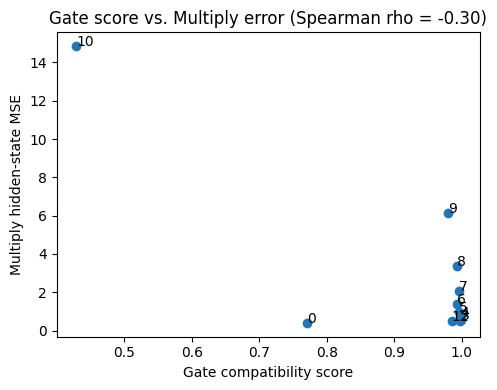

In [ ]:
# ============================================================
# 13. GATE-SCORE VALIDITY DIAGNOSTIC
# ============================================================

score_by_pair = (
    results_df[results_df["Method"] == "SG-SC"][["Pair_Start", "Score"]]
    .drop_duplicates("Pair_Start")
)
mult_mse_by_pair = (
    results_df[results_df["Method"] == "Multiply"][["Pair_Start", "Hidden_MSE"]]
    .drop_duplicates("Pair_Start")
)

diag_df = score_by_pair.merge(mult_mse_by_pair, on="Pair_Start").sort_values("Pair_Start")
spearman_rho = diag_df["Score"].corr(diag_df["Hidden_MSE"], method="spearman")

print("Gate score vs. Multiply's hidden-state MSE, per pair:")
print(diag_df.to_string(index=False))
print(f"\nSpearman correlation (n={len(diag_df)}): {spearman_rho:.3f}")
print("Expected sign: negative (higher compatibility -> lower Multiply error).")
print("With n=11 this is indicative, not conclusive -- report it as such.")

fig, ax = plt.subplots(figsize=(5, 4))
ax.scatter(diag_df["Score"], diag_df["Hidden_MSE"])
for _, row in diag_df.iterrows():
    ax.annotate(int(row["Pair_Start"]), (row["Score"], row["Hidden_MSE"]))
ax.set_xlabel("Gate compatibility score")
ax.set_ylabel("Multiply hidden-state MSE")
ax.set_title(f"Gate score vs. Multiply error (Spearman rho = {spearman_rho:.2f})")
plt.tight_layout()
diag_df.to_csv(f"{OUTPUT_DIR}/sgsc_gate_diagnostic.csv", index=False)
plt.savefig(f"{OUTPUT_DIR}/gate_score_diagnostic.png", dpi=150)
plt.show()

## 13B. Diagnostic: interpolation curve (is the optimum actually intermediate?)

Everything so far picks a single `w` per pair via Stage 2. This section
instead sweeps `w` across a fixed grid for a few representative pairs
(first, one from the middle, last) directly, bypassing the gate and
Stage-2 weighting entirely, to answer a more basic question: **is there
even a `w` strictly between 0 and 1 that beats both endpoints?** If the
curve is monotonic (best PPL always at `w=0` or `w=1`), then Stage 3's
whole reason for existing -- picking an interpolation point -- doesn't
hold for that pair, and SG-SC should behave like whichever endpoint wins,
not like a blend.

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

...

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

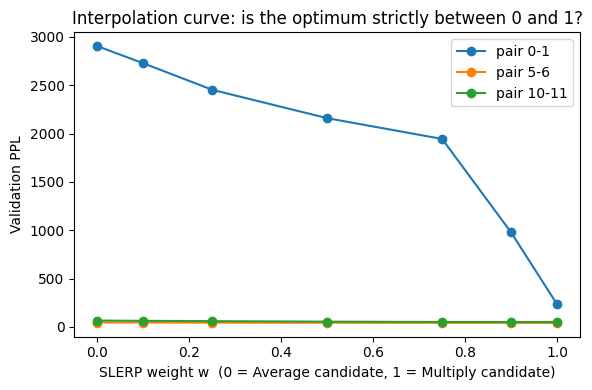

 Pair_Start  Pair    w         PPL
          0   0-1 0.00 2904.462067
          0   0-1 0.10 2727.479484
          0   0-1 0.25 2453.111323
          0   0-1 0.50 2159.574471
          0   0-1 0.75 1944.922367
          0   0-1 0.90  978.698118
          0   0-1 1.00  235.278583
          5   5-6 0.00   45.938737
          5   5-6 0.10   45.418837
          5   5-6 0.25   44.693169
          5   5-6 0.50   43.623789
          5   5-6 0.75   42.745740
          5   5-6 0.90   42.332359
          5   5-6 1.00   42.116310
         10 10-11 0.00   65.935648
         10 10-11 0.10   63.451146
         10 10-11 0.25   59.933997
         10 10-11 0.50   54.880624
         10 10-11 0.75   51.551553
         10 10-11 0.90   51.045068
         10 10-11 1.00   51.748301
pair 0-1: best w = 1.0 -> MULTIPLY endpoint
pair 5-6: best w = 1.0 -> MULTIPLY endpoint
pair 10-11: best w = 0.9 -> INTERMEDIATE


In [ ]:
# ============================================================
# 13B. INTERPOLATION CURVE (Experiment B)
# ============================================================

W_SWEEP = [0.0, 0.1, 0.25, 0.5, 0.75, 0.9, 1.0]
REPRESENTATIVE_PAIRS = sorted(set([PAIR_STARTS[0], PAIR_STARTS[len(PAIR_STARTS) // 2], PAIR_STARTS[-1]]))

sweep_rows = []
for L in REPRESENTATIVE_PAIRS:
    fitted = all_fitted_maps[L]
    A1, b1, A2, b2 = fitted["A1"], fitted["b1"], fitted["A2"], fitted["b2"]
    cand_avg = (0.5 * A1 + 0.5 * A2, 0.5 * b1 + 0.5 * b2)
    cand_mul = (A1 @ A2, b1 @ A2 + b2)

    for w in W_SWEEP:
        A_w, b_w = slerp_blend(cand_avg, cand_mul, w)
        m = build_affine_merged_model(L, A_w, b_w).to(DEVICE)
        sweep_rows.append({
            "Pair_Start": L, "Pair": f"{L}-{L+1}", "w": w,
            "PPL": calculate_ppl(m, validation_text),
        })
        free_model(m)

sweep_df = pd.DataFrame(sweep_rows)
sweep_df.to_csv(f"{OUTPUT_DIR}/sgsc_interpolation_sweep.csv", index=False)

fig, ax = plt.subplots(figsize=(6, 4))
for L in REPRESENTATIVE_PAIRS:
    sub = sweep_df[sweep_df["Pair_Start"] == L].sort_values("w")
    ax.plot(sub["w"], sub["PPL"], marker="o", label=f"pair {L}-{L+1}")
ax.set_xlabel("SLERP weight w  (0 = Average candidate, 1 = Multiply candidate)")
ax.set_ylabel("Validation PPL")
ax.set_title("Interpolation curve: is the optimum strictly between 0 and 1?")
ax.legend()
plt.tight_layout()
plt.savefig(f"{OUTPUT_DIR}/interpolation_curve.png", dpi=150)
plt.show()

print(sweep_df.to_string(index=False))
for L in REPRESENTATIVE_PAIRS:
    sub = sweep_df[sweep_df["Pair_Start"] == L].sort_values("PPL")
    best_w = sub.iloc[0]["w"]
    verdict = "INTERMEDIATE" if 0.0 < best_w < 1.0 else ("AVERAGE endpoint" if best_w == 0.0 else "MULTIPLY endpoint")
    print(f"pair {L}-{L+1}: best w = {best_w} -> {verdict}")

## 14. Final test-set check

Uses the exact `(pair, method, tau, w_min, w_max)` selected on validation in
Section 12 -- not the global defaults -- fixing v1's disconnect between
what the grid search found and what the final test cell evaluated.

In [ ]:
# ============================================================
# 14. FINAL TEST-SET CHECK
# ============================================================

original_test_ppl = calculate_ppl(original_model, test_text)

fitted = all_fitted_maps[BEST_PAIR]
A1, b1, A2, b2 = fitted["A1"], fitted["b1"], fitted["A2"], fitted["b2"]

if BEST_METHOD in SGSC_MODES:
    mode = SGSC_MODES[BEST_METHOD]
    A_final, b_final, final_meta = make_sgsc_condition(
        A1, b1, A2, b2,
        fitted["Y1_calib"], fitted["Y2_calib"], fitted["X_calib"],
        BEST_TAU, BEST_W_MIN, BEST_W_MAX, mode=mode,
    )
elif BEST_METHOD == "CGOS":
    A_final, b_final, final_meta = cgos_select_operator(
        fitted["X_calib"], fitted["Y2_calib"], A1, b1, A2, b2
    )
    assert final_meta["Selected"] == results_df.loc[
        (results_df["Method"] == "CGOS") & (results_df["Pair_Start"] == BEST_PAIR), "Strategy"
    ].item()
elif BEST_METHOD == "Random-Weight Average":
    rwa_seeds = [SEED + 1000 * BEST_PAIR + run for run in range(RANDOM_RUNS)]
    A_final, b_final = make_random_weight_affine_condition(A2, b2, seed=rwa_seeds[0])
    final_meta = {"seeds": rwa_seeds}
else:
    A_final, b_final = make_affine_conditions(A1, b1, A2, b2)[BEST_METHOD]
    final_meta = {}

final_model = build_affine_merged_model(BEST_PAIR, A_final, b_final).to(DEVICE)

final_test_ppl = calculate_ppl(final_model, test_text)
if BEST_METHOD == "Random-Weight Average":
    rwa_test_ppls = [final_test_ppl]
    for s in rwa_seeds[1:]:
        _m = build_affine_merged_model(BEST_PAIR, *make_random_weight_affine_condition(A2, b2, seed=s)).to(DEVICE)
        rwa_test_ppls.append(calculate_ppl(_m, test_text))
        free_model(_m)
    final_test_ppl = float(np.mean(rwa_test_ppls))
final_params = parameter_count(final_model)
final_latency_mean, final_latency_std = measure_latency(final_model, test_text)

print("\n===== FINAL SELECTED TEST RESULT =====")
print("Original Test PPL     :", original_test_ppl)
print("Selected pair          :", f"{BEST_PAIR}-{BEST_PAIR+1}")
print("Selected method        :", BEST_METHOD)
if BEST_METHOD in SGSC_MODES:
    print("Selected (tau, w_min, w_max):", BEST_TAU, BEST_W_MIN, BEST_W_MAX)
    print("Gate/weight metadata at test time:", final_meta)
if BEST_METHOD == "CGOS":
    print("CGOS calibration selection:", final_meta)
print("Compressed Test PPL    :", final_test_ppl)
print("Parameters              :", f"{final_params:,}")
print("Parameter reduction %  :", 100.0 * (1.0 - final_params / baseline_params))
print(f"Latency (ms)            : {final_latency_mean:.3f} +/- {final_latency_std:.3f}")

pd.DataFrame([{
    "Original_Test_PPL": original_test_ppl, "Pair": f"{BEST_PAIR}-{BEST_PAIR+1}", "Method": BEST_METHOD,
    "tau": np.nan if BEST_METHOD == "CGOS" else BEST_TAU,
    "w_min": np.nan if BEST_METHOD == "CGOS" else BEST_W_MIN,
    "w_max": np.nan if BEST_METHOD == "CGOS" else BEST_W_MAX,
    "Validation_PPL": best_row_overall["PPL"],
    "Test_PPL": final_test_ppl, "Parameters": final_params, "Baseline_Parameters": baseline_params,
    "Param_Reduction_pct": 100.0 * (1.0 - final_params / baseline_params),
    "Latency_ms": final_latency_mean, "Latency_std_ms": final_latency_std,
    "Baseline_Latency_ms": baseline_latency_mean, "Baseline_Latency_std_ms": baseline_latency_std,
    "Meta": str(final_meta), "MODE": MODE,
}]).to_csv(f"{OUTPUT_DIR}/sgsc_final_test.csv", index=False)
free_model(final_model)

In [ ]:
import pandas as pd
import os

for f in [
    "cgos_diagnostic.csv",
    "cgos_selection_accuracy.csv",
    "sgsc_final_test.csv",
    "sgsc_summary.csv",
    "sgsc_candidate_pool.csv",
]:
    path = os.path.join(OUTPUT_DIR, f)
    print("\n" + "="*80)
    print(f)
    print("="*80)
    df = pd.read_csv(path)
    print("Shape:", df.shape)
    print(df.to_string(index=False))


cgos_diagnostic.csv
Shape: (11, 12)
 Pair_Start  Pair CGOS_Selected  E_remove     E_avg     E_mul  Validation_PPL_Remove  Validation_PPL_Average  Validation_PPL_Multiply  Validation_PPL_CGOS Validation_Best_Operator  CGOS_Matches_Validation_Best
          0   0-1      Multiply  8.796502  3.689672  0.416217            3748.340916             2904.462067               235.278583           235.278583                 Multiply                          True
          1   1-2      Multiply 22.440569 24.984171  0.489709              47.323135               56.224773                81.079952            81.079952                   Remove                         False
          2   2-3      Multiply 18.651186  5.999968  0.552724              57.169486               48.936199                50.924950            50.924950                  Average                         False
          3   3-4      Multiply  0.952363  0.824334  0.600349              53.252780               50.495093               